# Hospital infection control: do earlier transfers improve prediction?

**Complex Systems and Applications — completed Option 1**

The analysis below uses the published synthetic course data for the hospital infection
control project.

## Portfolio summary

This project asks whether earlier patient transfers improve prediction of a new simulated infection cluster over the next 14 days. Among 120 synthetic wards, 102 were eligible because they had no active cluster at the observation point. I compared logistic regression using occupancy and device-use share with the same model adding total incoming transfers and transfers from initially affected wards. Both used the same stratified 71/31 training/test split, with scaling fitted only on training data. Adding network features increased F1 from 0.435 to 0.737 and ROC AUC from 0.693 to 0.904; accuracy increased from 0.581 to 0.839. The network model missed five of twelve later clusters and produced no false alarms. Total incoming volume measures all recorded arrivals; the other feature counts arrivals from affected sources. These results describe one small synthetic test set and do not establish transmission or clinical usefulness. In practice, missed clusters could delay investigation and false alarms could divert staff; infection-control professionals would need to review any flags.

## Part 1: prepared data and focused exploration

**Prediction point:** the end of the 14-day transfer recording window. The two ward
attributes, earlier transfers and initial cluster status are known at this point.
The target describes a new simulated cluster over the following 14 days.

| File | Unit of observation | Contents |
|---|---|---|
| `data/hospital_wards.csv` | One ward | Identifier, occupancy ratio, device-use share, initial status and later outcome |
| `data/hospital_transfers.csv` | One ordered pair of wards | Source, destination and number of earlier transfers |

Local copies of the published course files are included for reproducibility. The loader
uses them first and falls back to the course URL only if a file is missing. The dataset
construction note is included in `sources/`; this notebook does not generate new data.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, confusion_matrix,
    precision_score, recall_score, roc_curve, ConfusionMatrixDisplay,
)

SEED = 123
DATA_BASE_URL = 'https://raw.githubusercontent.com/mikeauth/leap/main/hospital'
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data' / 'hospital_wards.csv').is_file():
    if (PROJECT_DIR / 'submission' / 'data' / 'hospital_wards.csv').is_file():
        PROJECT_DIR = PROJECT_DIR / 'submission'
    elif (PROJECT_DIR / 'hospital_capstone' / 'data' / 'hospital_wards.csv').is_file():
        PROJECT_DIR = PROJECT_DIR / 'hospital_capstone'
DATA_DIR = PROJECT_DIR / 'data'
FIGURE_DIR = PROJECT_DIR / 'figures'
RESULT_DIR = PROJECT_DIR / 'results'
for directory in (FIGURE_DIR, RESULT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BLUE = '#286B8A'
ORANGE = '#BC583A'
plt.rcParams.update({
    'figure.dpi': 115, 'savefig.dpi': 180, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'semibold',
})

def load_course_csv(filename):
    for local in (DATA_DIR / filename, PROJECT_DIR / filename):
        if local.is_file():
            print(f'Loaded local file: {local.relative_to(PROJECT_DIR)}')
            return pd.read_csv(local)
    url = f'{DATA_BASE_URL}/{filename}'
    print(f'Local file missing; reading course source: {url}')
    return pd.read_csv(url)

def save_figure(fig, filename):
    fig.savefig(FIGURE_DIR / filename, bbox_inches='tight', facecolor='white')

wards = load_course_csv('hospital_wards.csv')
transfers = load_course_csv('hospital_transfers.csv')
assert wards['ward_id'].is_unique
assert {'ward_id', 'occupancy_ratio', 'device_use_share',
        'active_cluster_at_start', 'new_cluster_later'} <= set(wards)
assert {'source_ward_id', 'destination_ward_id', 'transfer_count'} <= set(transfers)
assert wards['active_cluster_at_start'].isin([0, 1]).all()
assert wards[['occupancy_ratio', 'device_use_share']].notna().all().all()
assert wards['occupancy_ratio'].between(0, 1).all()
assert wards['device_use_share'].between(0, 1).all()
initially_active = wards['active_cluster_at_start'].eq(1)
assert wards.loc[initially_active, 'new_cluster_later'].isna().all()
assert wards.loc[~initially_active, 'new_cluster_later'].isin([0, 1]).all()

display(wards.head())
display(transfers.head())
print(f'Wards: {len(wards)} | Directed links: {len(transfers)} | '
      f'Initially affected: {initially_active.sum()}')

Loaded local file: data/hospital_wards.csv
Loaded local file: data/hospital_transfers.csv


,ward_id,occupancy_ratio,device_use_share,active_cluster_at_start,new_cluster_later
0,W001,0.758,0.187,1,NaN
1,W002,0.886,0.338,0,1.0
2,W003,0.533,0.197,0,0.0
3,W004,0.777,0.364,0,1.0
4,W005,0.775,0.446,0,1.0


,source_ward_id,destination_ward_id,transfer_count
0,W001,W006,4
1,W001,W042,6
2,W001,W093,9
3,W001,W111,5
4,W002,W050,3


Wards: 120 | Directed links: 420 | Initially affected: 18


### Focused EDA

Wards already affected at the start are ineligible for the later-onset prediction task.
Their blank targets mean **ineligible**, not a negative outcome. The exploratory plots
below describe the eligible sample. The features and the train/test split are fixed in
advance, so these plots are descriptive and do not drive any modelling choice.

Eligible: 102 | No later cluster: 63 | Later cluster: 39 (38.2%)


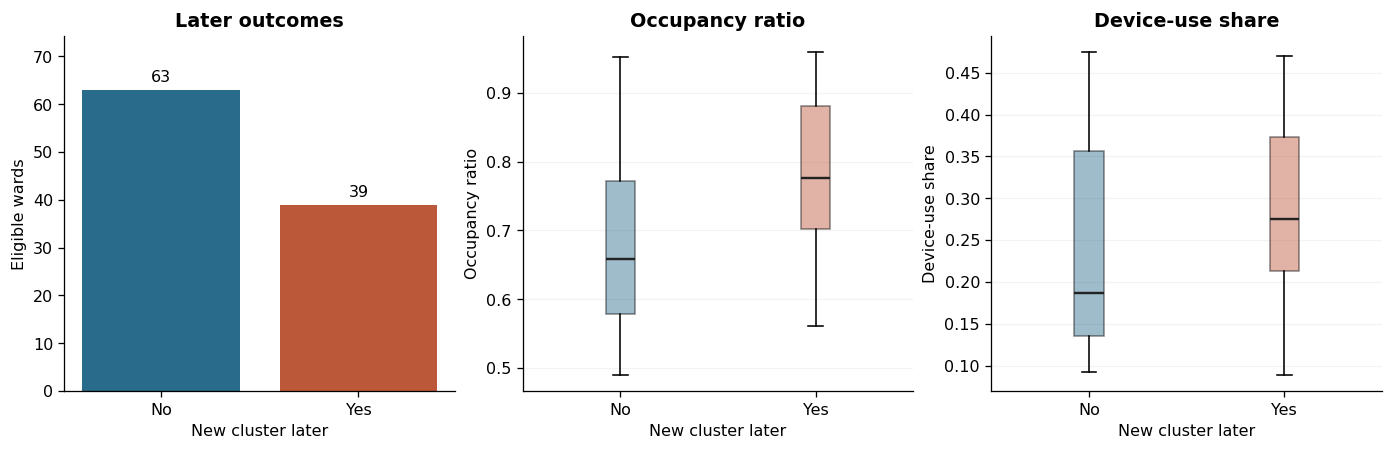

occupancy_ratio               device_use_share              
                              min median    max              min median    max
new_cluster_later                                                             
0.0                         0.490  0.659  0.953            0.092  0.187  0.475
1.0                         0.561  0.777  0.960            0.089  0.275  0.470

In [2]:
# Completed marker 1: eligible wards have no cluster active at the start.
eligible_eda = wards.loc[wards['active_cluster_at_start'].eq(0)].copy()
counts = (eligible_eda['new_cluster_later'].astype(int).value_counts()
          .reindex([0, 1], fill_value=0))
print(f'Eligible: {len(eligible_eda)} | No later cluster: {counts[0]} | '
      f'Later cluster: {counts[1]} ({counts[1] / len(eligible_eda):.1%})')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout='constrained')
bars = axes[0].bar(['No', 'Yes'], counts.to_numpy(), color=[BLUE, ORANGE])
axes[0].bar_label(bars, padding=3)
axes[0].set(xlabel='New cluster later', ylabel='Eligible wards', title='Later outcomes',
            ylim=(0, counts.max() * 1.18))
for ax, column, label in zip(
    axes[1:], ['occupancy_ratio', 'device_use_share'],
    ['Occupancy ratio', 'Device-use share'],
):
    groups = [eligible_eda.loc[eligible_eda['new_cluster_later'].eq(k), column]
              for k in [0, 1]]
    boxes = ax.boxplot(groups, patch_artist=True,
                       medianprops={'color': '#222222', 'linewidth': 1.5})
    ax.set_xticks([1, 2], ['No', 'Yes'])
    for box, color in zip(boxes['boxes'], [BLUE, ORANGE]):
        box.set_facecolor(color)
        box.set_alpha(.45)
    ax.set(xlabel='New cluster later', ylabel=label, title=label)
    ax.grid(axis='y', alpha=.15)
save_figure(fig, '01_focused_eda.png')
plt.show()

attribute_summary = eligible_eda.groupby('new_cluster_later')[
    ['occupancy_ratio', 'device_use_share']
].agg(['min', 'median', 'max'])
display(attribute_summary.round(3))

*Figure 1. Later outcomes and the two original attributes among eligible wards.*


**Interpretation.** There are 102 eligible wards: 39 develop a later simulated cluster
and 63 do not. The later-cluster group has higher median occupancy (0.777 versus 0.659)
and device-use share (0.275 versus 0.187). The boxplots and ranges overlap substantially,
so neither attribute separates the two classes cleanly.


## Part 2: directed, weighted transfer network

Each ward is a node. An edge from ward A to ward B means recorded transfers from A to B,
and its `transfer_count` is the number of transfers in the preceding window. All 120
wards remain in the graph, including the 18 excluded from the prediction sample.
Their known initial states are needed to calculate exposure at eligible wards.

- `incoming_volume`: the sum of transfer counts on every incoming edge.
- `from_active_volume`: the sum on incoming edges whose source ward was affected at the start.

Both features use information available at the observation point. Neither uses the later target.

In [3]:
G = nx.DiGraph()
G.add_nodes_from(wards['ward_id'])
valid_ids = set(wards['ward_id'])
assert transfers['source_ward_id'].isin(valid_ids).all()
assert transfers['destination_ward_id'].isin(valid_ids).all()
assert (transfers['source_ward_id'] != transfers['destination_ward_id']).all()
assert not transfers.duplicated(['source_ward_id', 'destination_ward_id']).any()
assert transfers['transfer_count'].gt(0).all()
assert transfers['transfer_count'].mod(1).eq(0).all()

for row in transfers.itertuples(index=False):
    # Completed marker 2: use the actual transfer count as the weight.
    G.add_edge(row.source_ward_id, row.destination_ward_id,
               transfer_count=int(row.transfer_count))

initial = wards.set_index('ward_id')['active_cluster_at_start']
wards['incoming_volume'] = [
    G.in_degree(ward_id, weight='transfer_count') for ward_id in wards['ward_id']
]
# Completed marker 3: select sources with initial status 1.
wards['from_active_volume'] = [
    sum(edge['transfer_count'] for source, _, edge in G.in_edges(ward_id, data=True)
        if initial.loc[source] == 1)
    for ward_id in wards['ward_id']
]

assert G.number_of_nodes() == len(wards)
assert G.number_of_edges() == len(transfers)
assert (wards['from_active_volume'] <= wards['incoming_volume']).all()
assert wards['incoming_volume'].sum() == transfers['transfer_count'].sum()

print(f'Nodes: {G.number_of_nodes()} | Directed links: {G.number_of_edges()} | '
      f'Transfers: {transfers["transfer_count"].sum()}')
display(wards[['ward_id', 'incoming_volume', 'from_active_volume']].head())

Nodes: 120 | Directed links: 420 | Transfers: 2101


,ward_id,incoming_volume,from_active_volume
0,W001,19,0
1,W002,42,15
2,W003,14,3
3,W004,30,0
4,W005,8,0


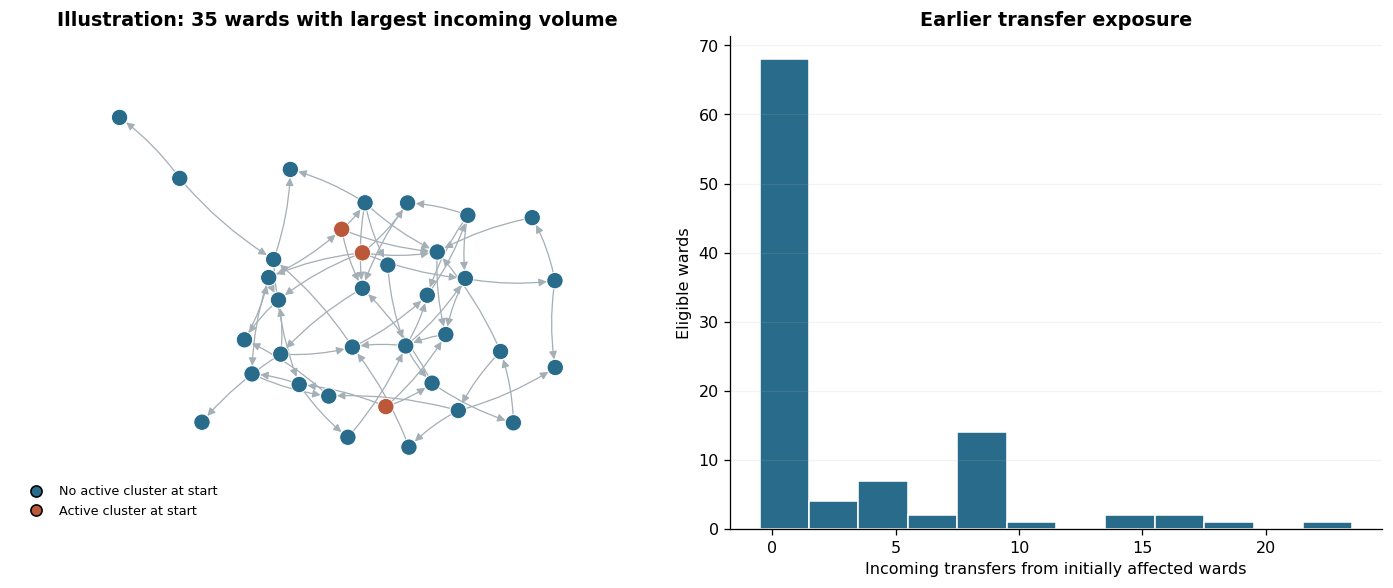

Eligible wards with zero transfers from initially affected wards: 65 of 102


In [4]:
shown = wards.nlargest(35, 'incoming_volume')['ward_id'].tolist()
small = G.subgraph(shown)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.0), layout='constrained')
# Lay out an explicitly ordered undirected copy. Iterating a subgraph view (or calling
# to_undirected()) depends on hash-randomised sets, which would move the nodes on every
# run. The graph drawn below is still the directed subgraph.
layout_graph = nx.Graph()
layout_graph.add_nodes_from(shown)
layout_graph.add_edges_from(sorted(tuple(sorted(e)) for e in small.edges()))
pos = nx.spring_layout(layout_graph, seed=42, weight=None)
# Draw in an explicit order as well: the subgraph view iterates in hash-randomised
# set order, and a different draw order composites the overlaps differently.
node_colors = [ORANGE if initial.loc[node] == 1 else BLUE for node in shown]
shown_edges = sorted(small.edges())
nx.draw_networkx_nodes(small, pos, ax=axes[0], node_size=105, nodelist=shown,
                        node_color=node_colors, edgecolors='white', linewidths=.6)
nx.draw_networkx_edges(small, pos, ax=axes[0], node_size=105, edgelist=shown_edges,
                        edge_color='#A5AFB6', width=.8, arrows=True,
                        arrowsize=10, connectionstyle='arc3,rad=0.08')
axes[0].legend(handles=[
    Line2D([0], [0], marker='o', color='none', markerfacecolor=BLUE,
           label='No active cluster at start', markersize=7),
    Line2D([0], [0], marker='o', color='none', markerfacecolor=ORANGE,
           label='Active cluster at start', markersize=7),
], loc='lower left', frameon=False, fontsize=8)
axes[0].set_title('Illustration: 35 wards with largest incoming volume')
axes[0].margins(.18)
axes[0].axis('off')

exposure = wards.loc[wards['active_cluster_at_start'].eq(0), 'from_active_volume']
axes[1].hist(exposure, bins=np.arange(-.5, exposure.max() + 2, 2),
              color=BLUE, edgecolor='white')
axes[1].set(xlabel='Incoming transfers from initially affected wards',
             ylabel='Eligible wards', title='Earlier transfer exposure')
axes[1].grid(axis='y', alpha=.15)
save_figure(fig, '02_transfer_network.png')
plt.show()
print(f'Eligible wards with zero transfers from initially affected wards: '
      f'{exposure.eq(0).sum()} of {len(exposure)}')

*Figure 2. Left: an induced subgraph of 35 wards, coloured only by initial status;
arrows show direction and edge widths are uniform. Right: exposure among all 102
eligible wards; 65 have zero recorded transfers from initially affected sources.
The plotted subset omits other wards and links, but all features use the full graph.*


**Interpretation.** A high `from_active_volume` means a ward received many recorded
transfers from source wards that had an active cluster at the observation point; it
does not identify infected patients or prove a transmission route. Outgoing transfers
describe patients leaving that ward, so reversing the edges would measure a different exposure.


### Feature verification: worked calculation for Ward W002

For ward W002, the incoming rows below give total volume 42. Only transfers from W020,
W042 and W047 contribute to `from_active_volume`, giving 6 + 5 + 4 = 15.
The initial states belong to the **sources**. W002's own initial state is zero.

In [5]:
example = transfers.loc[transfers['destination_ward_id'].eq('W002')].copy()
example['source_active_at_start'] = example['source_ward_id'].map(initial)
example['contribution_to_from_active'] = (
    example['transfer_count'] * example['source_active_at_start']
)
display(example.reset_index(drop=True))
print('W002 incoming_volume =', example['transfer_count'].sum())
print('W002 from_active_volume =', example['contribution_to_from_active'].sum())

,source_ward_id,destination_ward_id,transfer_count,source_active_at_start,contribution_to_from_active
0,W020,W002,6,1,6
1,W042,W002,5,1,5
2,W047,W002,4,1,4
3,W059,W002,6,0,0
4,W073,W002,9,0,0
5,W078,W002,2,0,0
6,W082,W002,1,0,0
7,W104,W002,9,0,0


W002 incoming_volume = 42
W002 from_active_volume = 15


## Part 3: a fair logistic regression comparison

**Model A:** occupancy ratio and device-use share.
**Model B:** the same attributes plus incoming volume and volume from initially affected wards.

Both models use the same eligible wards, a single stratified split with `random_state=123`,
and a 30% test fraction. Each pipeline fits its scaler and logistic regression using
only the training rows. Logistic regression uses the default L2 regularization and
`C=1.0`; no hyperparameters or thresholds are tuned on the test set.
Hard predictions use the classifier's default decision boundary at probability 0.5.

This evaluates previously unlabelled wards in one network whose earlier links and initial
states are already known. It does not test forecasting a new time window or transferring
the model to an independent hospital network.

In [6]:
eligible = (wards.loc[wards['active_cluster_at_start'].eq(0)]
            .set_index('ward_id').copy())
y = eligible['new_cluster_later'].astype(int)
# Completed marker 4: reserve 30% for testing.
train_ids, test_ids = train_test_split(
    y.index, test_size=.30, stratify=y, random_state=SEED,
)
original = ['occupancy_ratio', 'device_use_share']
# Completed marker 5: add the source-state-weighted incoming volume.
with_network = original + ['incoming_volume', 'from_active_volume']

assert set(train_ids).isdisjoint(test_ids)
assert set(train_ids) | set(test_ids) == set(y.index)
assert 'new_cluster_later' not in with_network
split_counts = pd.DataFrame({
    'Training': y.loc[train_ids].value_counts().reindex([0, 1], fill_value=0),
    'Test': y.loc[test_ids].value_counts().reindex([0, 1], fill_value=0),
}).rename_axis('Later cluster')
display(split_counts)
print(f'Training wards: {len(train_ids)} | Test wards: {len(test_ids)}')

def fit_and_score(columns):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000),
    )
    X_train = eligible.loc[train_ids, columns]
    X_test = eligible.loc[test_ids, columns]
    model.fit(X_train, y.loc[train_ids])
    predicted = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    scores = {
        'Accuracy': accuracy_score(y.loc[test_ids], predicted),
        'F1': f1_score(y.loc[test_ids], predicted, zero_division=0),
        # Completed marker 6: AUC receives probabilities, not binary decisions.
        'ROC AUC': roc_auc_score(y.loc[test_ids], probabilities),
    }
    return scores, predicted, probabilities

base_scores, base_pred, base_prob = fit_and_score(original)
network_scores, network_pred, network_prob = fit_and_score(with_network)
results = pd.DataFrame(
    [base_scores, network_scores], index=['Original ward features', 'Ward + network features'],
)
display(results.round(3))
display((results.iloc[1] - results.iloc[0]).to_frame('Network minus original').round(3))
results.to_csv(RESULT_DIR / 'required_model_metrics.csv', index_label='Model')

predictions = pd.DataFrame({
    'ward_id': test_ids,
    'new_cluster_later': y.loc[test_ids].to_numpy(),
    'model_A_probability': base_prob, 'model_A_prediction': base_pred,
    'model_B_probability': network_prob, 'model_B_prediction': network_pred,
})
predictions.to_csv(RESULT_DIR / 'test_predictions.csv', index=False)


,Training,Test
Later cluster,,
0,44,19
1,27,12


Training wards: 71 | Test wards: 31


,Accuracy,F1,ROC AUC
Original ward features,0.581,0.435,0.693
Ward + network features,0.839,0.737,0.904


,Network minus original
Accuracy,0.258
F1,0.302
ROC AUC,0.211


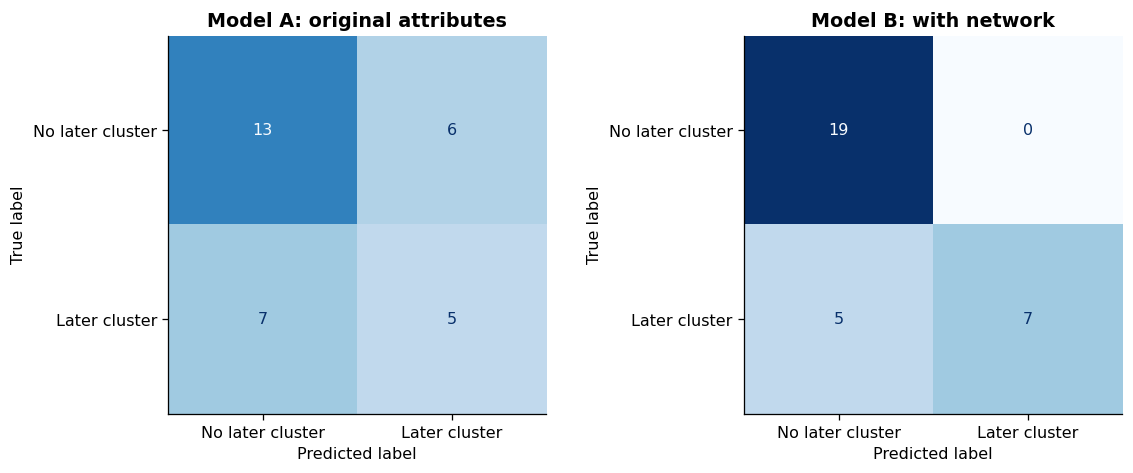

,TN,FP,FN,TP,Precision,Recall
Model,,,,,,
Model A: original attributes,13,6,7,5,0.455,0.417
Model B: with network,19,0,5,7,1.000,0.583


Always predicting the training majority class (0): accuracy = 0.613, F1 = 0.000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), layout='constrained')
error_rows = []
for ax, predicted, title in zip(
    axes, [base_pred, network_pred], ['Model A: original attributes', 'Model B: with network'],
):
    ConfusionMatrixDisplay.from_predictions(
        y.loc[test_ids], predicted, ax=ax, labels=[0, 1],
        display_labels=['No later cluster', 'Later cluster'],
        colorbar=False, cmap='Blues', values_format='d',
    )
    ax.images[0].set_clim(0, int((y.loc[test_ids] == 0).sum()))
    ax.set_title(title)
    tn, fp, fn, tp = confusion_matrix(y.loc[test_ids], predicted, labels=[0, 1]).ravel()
    error_rows.append({
        'Model': title, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Precision': precision_score(y.loc[test_ids], predicted, zero_division=0),
        'Recall': recall_score(y.loc[test_ids], predicted),
    })
save_figure(fig, '03_confusion_matrices.png')
plt.show()
errors = pd.DataFrame(error_rows).set_index('Model')
display(errors.round(3))
errors.to_csv(RESULT_DIR / 'required_model_errors.csv')

# A simple reference helps interpret accuracy in an imbalanced sample.
majority_class = int(y.loc[train_ids].mode().iloc[0])
majority_pred = np.full(len(test_ids), majority_class)
print(f'Always predicting the training majority class ({majority_class}): '
      f'accuracy = {accuracy_score(y.loc[test_ids], majority_pred):.3f}, '
      f'F1 = {f1_score(y.loc[test_ids], majority_pred, zero_division=0):.3f}')

*Figure 3. Confusion matrices at the default decision threshold, with the same colour scale.*


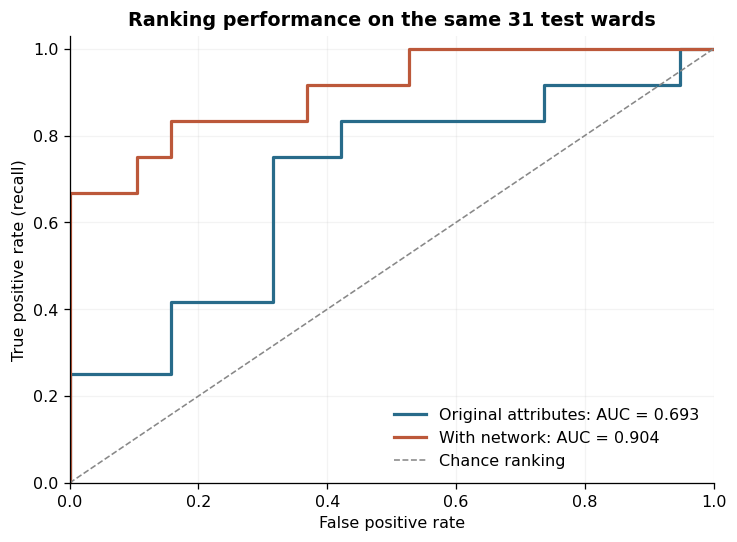

In [8]:
fig, ax = plt.subplots(figsize=(6.3, 4.6), layout='constrained')
for probabilities, label, color in [
    (base_prob, 'Original attributes', BLUE),
    (network_prob, 'With network', ORANGE),
]:
    fpr, tpr, _ = roc_curve(y.loc[test_ids], probabilities)
    auc = roc_auc_score(y.loc[test_ids], probabilities)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{label}: AUC = {auc:.3f}')
ax.plot([0, 1], [0, 1], '--', color='#888888', linewidth=1, label='Chance ranking')
ax.set(xlabel='False positive rate', ylabel='True positive rate (recall)',
       title='Ranking performance on the same 31 test wards',
       xlim=(0, 1), ylim=(0, 1.03))
ax.legend(loc='lower right', frameon=False)
ax.grid(alpha=.15)
save_figure(fig, '04_roc_curves.png')
plt.show()

*Figure 4. ROC curves calculated from predicted probabilities on the same test wards.*


### Final interpretation

Adding the two network features improves all three metrics on this fixed test set:
accuracy rises from 0.581 to 0.839, F1 from 0.435 to 0.737 and ROC AUC from 0.693
to 0.904. These are observed differences on 31 wards, not estimates of a guaranteed
benefit in a new hospital.

Model A identifies 5 of 12 later clusters, misses 7 and raises 6 false alarms. Model B
identifies 7, misses 5 and raises no false alarms. Its recall is therefore 7/12 = 0.583:
the high precision of 1.000 does not mean it detects every later cluster. One changed
test prediction would change accuracy by about 3.2 percentage points.

The two network features have different meanings. Total incoming volume measures all
earlier arrivals. Volume from initially affected sources incorporates information about
the known state of neighbouring wards. Their predictive association cannot establish
which patients were infected, when transmission happened, or whether transfers caused
clusters. The source status is measured at the observation point, not continuously
throughout the preceding transfer window.

The synthetic outcome rule deliberately includes both network features. That makes this
a test of recovering signal in a small constructed sample. The single split, synthetic
setting and absence of independent hospitals limit any broader conclusion. Wards also
share a graph; the random node split does not establish independence or generalization
to a different network.

**Ethics.** If such flags were ever considered in practice, missed clusters could delay
investigation, while false alarms could divert infection-control resources and burden
patients and staff. Infection-control professionals would need to review flags together
with clinical evidence before action. These synthetic results do not support deployment.


### Reflection

The comparison is reproducible because both models use identical rows and training-only
scaling. The main conceptual challenge is keeping the prediction sample separate from
the graph: initially affected wards are excluded from the target but retained as known
sources of incoming transfers. With more time, repeated validation within the training
data could assess sensitivity to the split, followed by evaluation on genuinely new
data; realistic clinical conclusions would require an appropriate real dataset and study
design. The part worth carrying to other networked systems is the bookkeeping: a
component's own measurements and the connections that link it to its neighbours are two
different things, and both have to be kept free of later information for the comparison
to mean anything.

## Sources

The CSVs are the published course data, downloaded on 30 September 2026.

- [Hospital ward source CSV](https://raw.githubusercontent.com/mikeauth/leap/main/hospital/hospital_wards.csv)
- [Hospital transfer source CSV](https://raw.githubusercontent.com/mikeauth/leap/main/hospital/hospital_transfers.csv)
- [Supplied synthetic-data construction note](sources/Synthetic_Hospital_Data_Construction.pdf)
- Course brief and portfolio instructions: supplied with the assignment.
- [scikit-learn: avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [NetworkX: directed graphs](https://networkx.org/documentation/stable/reference/classes/digraph.html)
